# Method 1: continuous-height LARIAC–assessor floor-area agreement

This notebook scores single-AIN parcel sites by agreement between the 2017 continuous-height LARIAC floor-area estimate (`footprint × height / 10 ft`) and assessor `SQFTmain`, within assessor use type. The residual screen is the primary Method 1 result; the ratio screen is retained as a secondary comparison. The former integer-floor estimate appears only in the sensitivity appendix.

In [1]:
from pathlib import Path
import sqlite3
import textwrap

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import mannwhitneyu

def find_project_root(start):
    start = Path(start).resolve()
    for candidate in [start, *start.parents]:
        if (candidate / 'src').exists() and (candidate / 'data').exists():
            return candidate
    raise RuntimeError('Could not locate the NDSC_HiddenHousing project root')

PROJECT_ROOT = find_project_root(Path.cwd())
CITY_OUTPUT = PROJECT_ROOT / 'data/03_processed/city_of_la'
CITY_TILE_ROOT = PROJECT_ROOT / 'data/02_intermediate/city_of_la/tiles'
MASTER_DB = PROJECT_ROOT / 'data/01_source/all_parcel_data.sqlite'
CURRENT_UDU_REPORT = PROJECT_ROOT / 'data/01_source/UDU Report 02_10_2026.csv'
ROOF_CLASSIFICATION = (
    PROJECT_ROOT / 'data/03_processed/roof_slope_udu_ept_cleaned'
    / 'udu_300_tracts_roof_classification.parquet'
)
MIN_KNOWN_UDU_PER_USE_TYPE = 5

In [2]:
def normalize_ain(values):
    return (
        values.astype('string').str.strip().str.replace('-', '', regex=False)
        .str.replace(r'\.0$', '', regex=True).str.zfill(10)
    )

def load_city_table(filename, columns):
    published = CITY_OUTPUT / filename
    if published.exists():
        return pd.read_parquet(published, columns=columns), 'published city output'
    manifests = sorted(CITY_TILE_ROOT.glob('*/manifest.json'))
    paths = [manifest.parent / filename for manifest in manifests]
    paths = [path for path in paths if path.exists()]
    if not paths:
        raise RuntimeError(f'No completed output found for {filename}')
    frames = [pd.read_parquet(path, columns=columns) for path in paths]
    return pd.concat(frames, ignore_index=True), f'{len(paths)} completed tiles'

assessor, assessor_scope = load_city_table(
    'assessor_ain_metrics_2017.parquet',
    ['AIN', 'site_id', 'assessor.sqft'],
)
assessor['AIN'] = normalize_ain(assessor['AIN'])
assessor = assessor.drop_duplicates('AIN').reset_index(drop=True)

sites, site_scope = load_city_table(
    'parcel_metrics_2017.parquet',
    [
        'site_id', 'building.floor_area',
        'building.floor_area_continuous', 'assessor.ain_count',
    ],
)
sites = sites.drop_duplicates('site_id').reset_index(drop=True)

roof_classification = pd.read_parquet(
    ROOF_CLASSIFICATION,
    columns=[
        'AIN', 'BLD_ID', 'median_slope_clean_deg', 'roof_type_clean',
    ],
)
roof_classification['AIN'] = normalize_ain(roof_classification['AIN'])
roof_classification['BLD_ID'] = roof_classification['BLD_ID'].astype('string')
building_footprints, building_scope = load_city_table(
    'building_metrics_2017.parquet', ['structure_id', 'shape.area']
)
building_footprints['structure_id'] = (
    building_footprints['structure_id'].astype('string')
)
building_footprints['shape.area'] = pd.to_numeric(
    building_footprints['shape.area'], errors='coerce'
)
building_footprints = building_footprints.drop_duplicates('structure_id')

# Pick the largest footprint before deciding whether its roof is usable.
# This avoids substituting a smaller classified outbuilding when the main
# building has too few clean LiDAR points.
largest_building_roof = (
    roof_classification.merge(
        building_footprints, left_on='BLD_ID', right_on='structure_id',
        how='left', validate='one_to_one',
    )
    .dropna(subset=['AIN', 'shape.area'])
    .sort_values(
        ['AIN', 'shape.area', 'BLD_ID'], ascending=[True, False, True]
    )
    .drop_duplicates('AIN')
    .rename(columns={
        'BLD_ID': 'largest_building_id',
        'shape.area': 'largest_building_footprint_sqft',
        'median_slope_clean_deg': 'largest_building_median_slope_deg',
        'roof_type_clean': 'largest_building_roof_type',
    })
)
largest_building_roof['largest_building_roof_type'] = (
    largest_building_roof['largest_building_roof_type']
    .replace({'pitched': 'sloped', 'insufficient_points': pd.NA})
)
largest_building_roof = largest_building_roof[[
    'AIN', 'largest_building_id', 'largest_building_footprint_sqft',
    'largest_building_median_slope_deg', 'largest_building_roof_type',
]]

with sqlite3.connect(MASTER_DB) as connection:
    master = pd.read_sql_query(
        'SELECT AssessorID, usecodedescchar2_2016 FROM all_parcel_data',
        connection,
    )
master['AIN'] = normalize_ain(master['AssessorID'])
if master['AIN'].duplicated().any():
    raise ValueError('Master parcel data must contain one row per normalized AIN')
master = master.rename(columns={'usecodedescchar2_2016': 'SpecificUseType'})

udu_report = pd.read_csv(
    CURRENT_UDU_REPORT, usecols=['assessor_parcel_number'], encoding='utf-8-sig'
)
udu_report['AIN'] = normalize_ain(udu_report['assessor_parcel_number'])
known_udu_ains = set(udu_report['AIN'].dropna())

method1_input = (
    assessor.merge(sites, on='site_id', how='inner', validate='many_to_one')
    .merge(
        master[['AIN', 'SpecificUseType']],
        on='AIN', how='left', validate='one_to_one',
    )
    .merge(
        largest_building_roof, on='AIN', how='left', validate='one_to_one',
    )
)
method1_input['is_known_udu'] = method1_input['AIN'].isin(known_udu_ains)
method1_input = method1_input.loc[
    method1_input['assessor.ain_count'].eq(1)
    & method1_input['assessor.sqft'].gt(0)
    & method1_input['building.floor_area_continuous'].gt(0)
    & method1_input['SpecificUseType'].notna()
].copy()

use_type_summary = method1_input.groupby('SpecificUseType').agg(
    parcels=('AIN', 'size'),
    known_udu=('is_known_udu', 'sum'),
).sort_values(['known_udu', 'parcels'], ascending=False)
modeled_use_types = use_type_summary.index[
    use_type_summary['known_udu'].ge(MIN_KNOWN_UDU_PER_USE_TYPE)
].tolist()
method1_input = method1_input.loc[
    method1_input['SpecificUseType'].isin(modeled_use_types)
].copy()

display(pd.Series({
    'Assessor data scope': assessor_scope,
    'Parcel data scope': site_scope,
    'Building footprint data scope': building_scope,
    'Eligible single-AIN parcels': len(method1_input),
    'Modeled use types': len(modeled_use_types),
    'Parcels with flat/sloped largest-building roof': (
        method1_input['largest_building_roof_type'].notna().sum()
    ),
    'Known UDU parcels with flat/sloped roof': (
        method1_input.loc[
            method1_input['is_known_udu'], 'largest_building_roof_type'
        ].notna().sum()
    ),
}).to_frame('value'))
display(use_type_summary.loc[modeled_use_types].reset_index())

,value
Assessor data scope,36 completed tiles
Parcel data scope,36 completed tiles
Building footprint data scope,36 completed tiles
Eligible single-AIN parcels,535193
Modeled use types,6
Parcels with flat/sloped largest-building roof,121309
Known UDU parcels with flat/sloped roof,399


,SpecificUseType,parcels,known_udu
0,Five or More Units or Apartments (Any Combinat...,29213,180
1,"Double, Duplex, or Two Units",42868,90
2,Three Units (Any Combination),13650,74
3,Four Units (Any Combination),13396,39
4,Store Combination,5216,16
5,Single Family Residence,430850,10


## Main relationship

Both axes use logarithmic scales. The dashed line represents exact agreement. The gray sample is capped at 4,000 observations per use type for rendering, while every known UDU is retained.

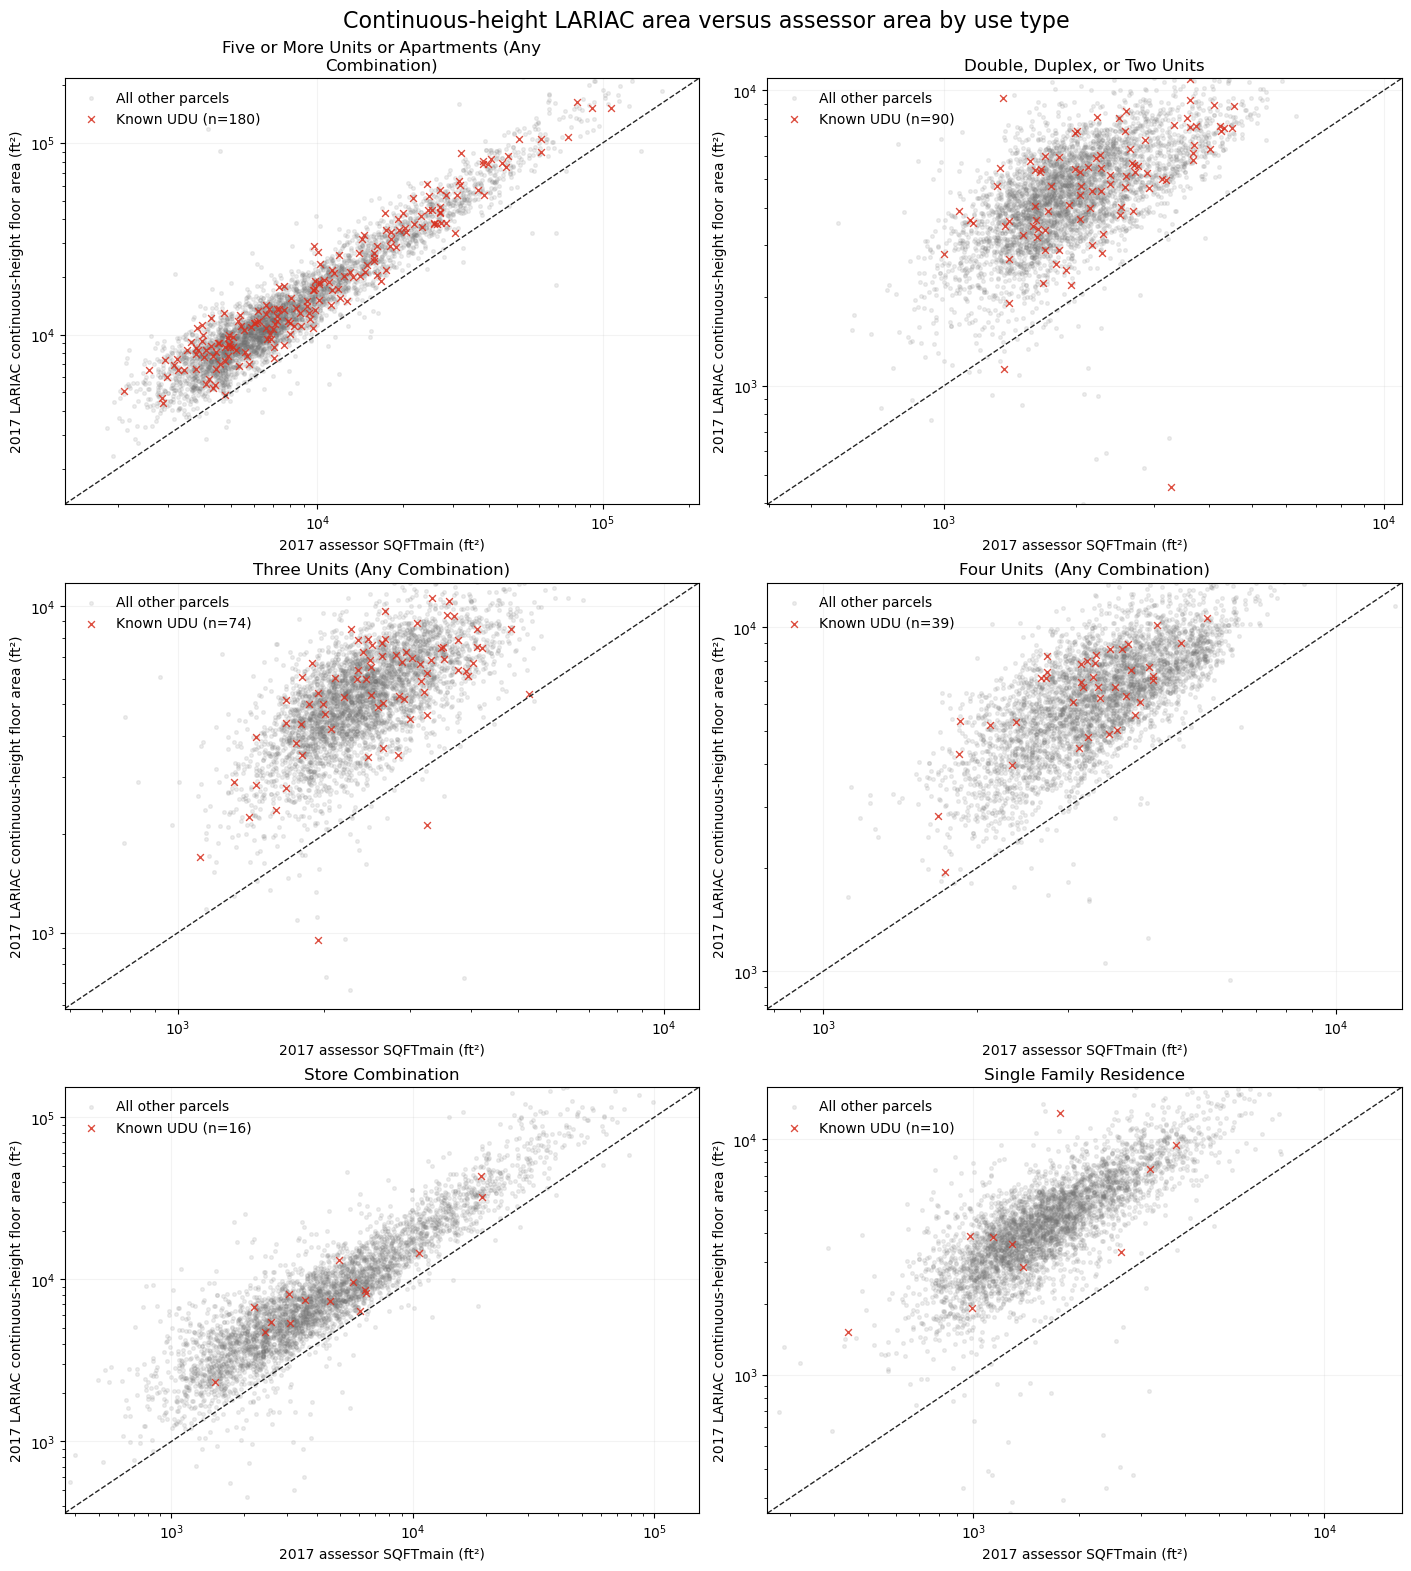

In [3]:
ncols = 2
nrows = int(np.ceil(len(modeled_use_types) / ncols))
fig, axes = plt.subplots(
    nrows, ncols, figsize=(14, 5.2 * nrows), constrained_layout=True
)
axes = np.atleast_1d(axes).ravel()
for ax, use_type in zip(axes, modeled_use_types):
    group = method1_input.loc[method1_input['SpecificUseType'].eq(use_type)]
    other = group.loc[~group['is_known_udu']]
    if len(other) > 4000:
        other = other.sample(4000, random_state=42)
    known = group.loc[group['is_known_udu']]
    ax.scatter(
        other['assessor.sqft'], other['building.floor_area_continuous'],
        s=7, alpha=0.12, color='#737373', rasterized=True,
        label='All other parcels',
    )
    ax.scatter(
        known['assessor.sqft'], known['building.floor_area_continuous'],
        s=24, alpha=0.85, color='#d7301f', marker='x', linewidth=1.0,
        label=f'Known UDU (n={len(known):,})',
    )
    values = pd.concat([
        group['assessor.sqft'], group['building.floor_area_continuous']
    ]).dropna()
    lower = max(10, float(values.quantile(0.001)))
    upper = float(values.quantile(0.995))
    ax.plot([lower, upper], [lower, upper], '--', color='#252525', linewidth=1)
    ax.set(xscale='log', yscale='log', xlim=(lower, upper), ylim=(lower, upper))
    ax.set_title('\n'.join(textwrap.wrap(use_type, 42)))
    ax.set_xlabel('2017 assessor SQFTmain (ft²)')
    ax.set_ylabel('2017 LARIAC continuous-height floor area (ft²)')
    ax.grid(alpha=0.15)
    ax.legend(frameon=False, loc='upper left')
for ax in axes[len(modeled_use_types):]:
    ax.remove()
fig.suptitle('Continuous-height LARIAC area versus assessor area by use type', fontsize=16)
plt.show()

### LARIAC-to-assessor ratio versus median roof slope

Each point uses the cleaned median slope of the largest building on the AIN. The horizontal line marks exact LARIAC–assessor agreement (`ratio = 1`), and the vertical line marks the 5° flat/sloped classification threshold. The y-axis is logarithmic; rendering is capped at 3,000 non-UDU parcels per roof class and use type, while every classified known UDU is retained.

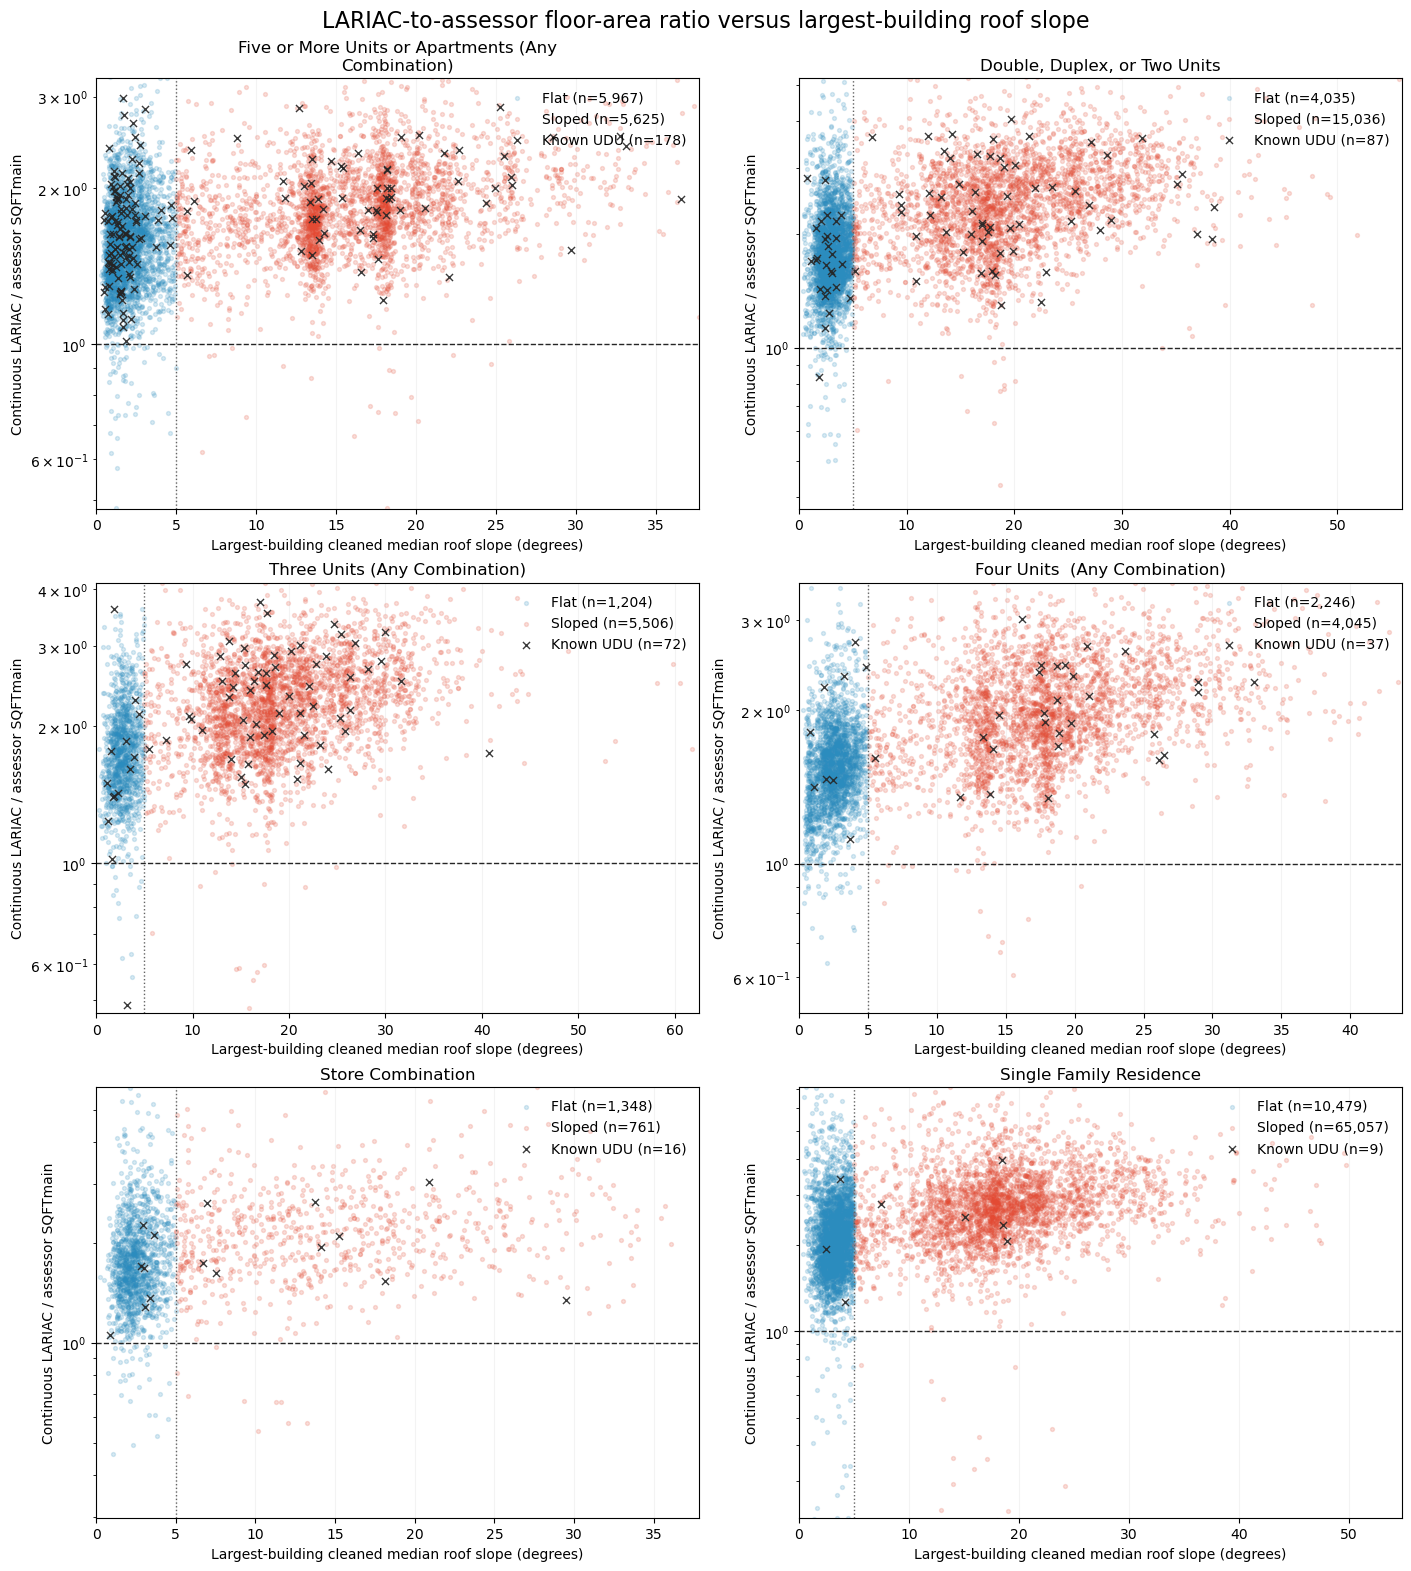

In [4]:
slope_ratio_analysis = method1_input.loc[
    method1_input['largest_building_roof_type'].isin(['flat', 'sloped'])
].copy()
slope_ratio_analysis['floor_area_to_sqft_ratio'] = (
    slope_ratio_analysis['building.floor_area_continuous']
    / slope_ratio_analysis['assessor.sqft']
)
slope_ratio_colors = {'flat': '#2b8cbe', 'sloped': '#e34a33'}

ncols = 2
nrows = int(np.ceil(len(modeled_use_types) / ncols))
fig, axes = plt.subplots(
    nrows, ncols, figsize=(14, 5.2 * nrows), constrained_layout=True
)
axes = np.atleast_1d(axes).ravel()
for ax, use_type in zip(axes, modeled_use_types):
    group = slope_ratio_analysis.loc[
        slope_ratio_analysis['SpecificUseType'].eq(use_type)
        & slope_ratio_analysis['largest_building_median_slope_deg'].notna()
        & slope_ratio_analysis['floor_area_to_sqft_ratio'].gt(0)
    ]
    for sample_seed, roof_type in enumerate(['flat', 'sloped'], start=51):
        roof_group = group.loc[
            group['largest_building_roof_type'].eq(roof_type)
        ]
        non_udu = roof_group.loc[~roof_group['is_known_udu']]
        if len(non_udu) > 3000:
            non_udu = non_udu.sample(3000, random_state=sample_seed)
        ax.scatter(
            non_udu['largest_building_median_slope_deg'],
            non_udu['floor_area_to_sqft_ratio'],
            s=8, alpha=0.18, color=slope_ratio_colors[roof_type], rasterized=True,
            label=f'{roof_type.title()} (n={len(roof_group):,})',
        )
    known = group.loc[group['is_known_udu']]
    ax.scatter(
        known['largest_building_median_slope_deg'],
        known['floor_area_to_sqft_ratio'],
        s=26, alpha=0.9, color='#252525', marker='x', linewidth=1.0,
        label=f'Known UDU (n={len(known):,})',
    )
    ratio_lower = max(0.1, float(group['floor_area_to_sqft_ratio'].quantile(0.001)))
    ratio_upper = float(group['floor_area_to_sqft_ratio'].quantile(0.995))
    slope_upper = max(10, float(
        group['largest_building_median_slope_deg'].quantile(0.995)
    ))
    ax.axhline(1, color='#252525', linestyle='--', linewidth=1)
    ax.axvline(5, color='#636363', linestyle=':', linewidth=1)
    ax.set(
        yscale='log', xlim=(0, slope_upper),
        ylim=(ratio_lower, ratio_upper),
    )
    ax.set_title('\n'.join(textwrap.wrap(use_type, 42)))
    ax.set_xlabel('Largest-building cleaned median roof slope (degrees)')
    ax.set_ylabel('Continuous LARIAC / assessor SQFTmain')
    ax.grid(alpha=0.15)
    ax.legend(frameon=False, loc='upper right')
for ax in axes[len(modeled_use_types):]:
    ax.remove()
fig.suptitle(
    'LARIAC-to-assessor floor-area ratio versus largest-building roof slope',
    fontsize=16,
)
plt.show()

In [5]:
def build_method1_features(
    data,
    percentile_cutoff=0.025,
    minimum_raw_residual=0.0,
    ratio_percentile_cutoff=0.05,
    *,
    ain_col='AIN',
    use_type_col='SpecificUseType',
    lariac_floor_area_col='building.floor_area_continuous',
    assessor_area_col='assessor.sqft',
):
    """Build Method 1 agreement features at the single-AIN parcel level.

    The LARIAC input defaults to footprint × height / 10 ft. Two screens
    are retained side by side. The residual screen flags the
    closest absolute agreement within use type. The ratio screen flags the
    lowest LARIAC floor area / assessor SQFTmain within use type: parcels
    where the assessor records at least as much area as the imagery shows,
    leaving the least room for unrecorded space.
    """
    required = {
        ain_col, use_type_col, lariac_floor_area_col, assessor_area_col
    }
    missing = required.difference(data.columns)
    if missing:
        raise ValueError(f'Missing Method 1 columns: {sorted(missing)}')

    roof_columns = [
        'largest_building_id', 'largest_building_footprint_sqft',
        'largest_building_median_slope_deg', 'largest_building_roof_type',
    ]
    roof_columns = [column for column in roof_columns if column in data]
    features = data[[ain_col, use_type_col, *roof_columns]].copy()
    features['floor_area_continuous_sqft'] = data[lariac_floor_area_col]
    features['raw_residual_sqft'] = (
        data[lariac_floor_area_col] - data[assessor_area_col]
    )
    features['_absolute_residual_sqft'] = features['raw_residual_sqft'].abs()
    features['abs_residual_pct_rank_by_use_type'] = (
        features.groupby(use_type_col)['_absolute_residual_sqft']
        .rank(method='average', pct=True)
    )
    features['method1_potential_nonudu'] = (
        features['abs_residual_pct_rank_by_use_type'].le(percentile_cutoff)
        & features['raw_residual_sqft'].gt(minimum_raw_residual)
    )
    features['floor_area_to_sqft_ratio'] = (
        data[lariac_floor_area_col]
        / data[assessor_area_col].where(data[assessor_area_col].gt(0))
    )
    features['log_floor_area_to_sqft_ratio'] = np.log(
        features['floor_area_to_sqft_ratio']
    )
    features['ratio_pct_rank_by_use_type'] = (
        features.groupby(use_type_col)['floor_area_to_sqft_ratio']
        .rank(method='average', pct=True)
    )
    features['method1_ratio_potential_nonudu'] = (
        features['ratio_pct_rank_by_use_type'].le(ratio_percentile_cutoff)
    )
    return (
        features[[
            ain_col, *roof_columns,
            'floor_area_continuous_sqft', 'raw_residual_sqft',
            'abs_residual_pct_rank_by_use_type', 'method1_potential_nonudu',
            'floor_area_to_sqft_ratio', 'log_floor_area_to_sqft_ratio',
            'ratio_pct_rank_by_use_type',
            'method1_ratio_potential_nonudu',
        ]]
        .rename(columns={ain_col: 'AIN'})
        .sort_values('AIN')
        .reset_index(drop=True)
    )

method1_features = build_method1_features(method1_input)
method1_output = method1_features[['AIN', 'method1_potential_nonudu']].copy()
display(pd.Series({
    'Output AINs': len(method1_features),
    'Residual screen potential non-UDU AINs': int(method1_features['method1_potential_nonudu'].sum()),
    'Residual screen share': method1_features['method1_potential_nonudu'].mean(),
    'Ratio screen potential non-UDU AINs': int(method1_features['method1_ratio_potential_nonudu'].sum()),
    'Ratio screen share': method1_features['method1_ratio_potential_nonudu'].mean(),
    'AINs flagged by both screens': int((
        method1_features['method1_potential_nonudu']
        & method1_features['method1_ratio_potential_nonudu']
    ).sum()),
}).to_frame('value'))
known_udu_flags = method1_features.loc[
    method1_features['AIN'].isin(known_udu_ains)
]
display(pd.Series({
    'Known UDU AINs': len(known_udu_flags),
    'Known UDU flagged by residual screen': int(known_udu_flags['method1_potential_nonudu'].sum()),
    'Known UDU flagged by ratio screen': int(known_udu_flags['method1_ratio_potential_nonudu'].sum()),
}).to_frame('value'))
display(method1_features.head())
display(method1_output.head())

,value
Output AINs,535193.000000
Residual screen potential non-UDU AINs,11002.000000
Residual screen share,0.020557
Ratio screen potential non-UDU AINs,26756.000000
Ratio screen share,0.049993
AINs flagged by both screens,9466.000000


,value
Known UDU AINs,409
Known UDU flagged by residual screen,7
Known UDU flagged by ratio screen,22


,AIN,largest_building_id,largest_building_footprint_sqft,largest_building_median_slope_deg,largest_building_roof_type,floor_area_continuous_sqft,raw_residual_sqft,abs_residual_pct_rank_by_use_type,method1_potential_nonudu,floor_area_to_sqft_ratio,log_floor_area_to_sqft_ratio,ratio_pct_rank_by_use_type,method1_ratio_potential_nonudu
0,2004001003,<NA>,NaN,NaN,NaN,9127.40,7037.40,0.955968,False,4.367177,1.474117,0.960260,False
1,2004001004,<NA>,NaN,NaN,NaN,7448.74,4969.74,0.874527,False,3.004736,1.100190,0.670730,False
2,2004001005,<NA>,NaN,NaN,NaN,7991.85,5934.85,0.925909,False,3.885197,1.357174,0.920522,False
3,2004001008,<NA>,NaN,NaN,NaN,9220.63,6797.63,0.950978,False,3.805460,1.336437,0.909883,False
4,2004001009,<NA>,NaN,NaN,NaN,8626.21,6400.21,0.940910,False,3.875207,1.354599,0.919248,False


,AIN,method1_potential_nonudu
0,2004001003,False
1,2004001004,False
2,2004001005,False
3,2004001008,False
4,2004001009,False


## Largest-building roof type and floor-area agreement

The transferred roof-classification parquet covers buildings in the 300 census tracts with observed UDUs, rather than all of Los Angeles. Within that coverage, each AIN is assigned the roof class of its largest building by 2017 LARIAC footprint area. The source label `pitched` is reported here as `sloped`; a largest building with fewer than 100 accepted clean LiDAR points remains missing rather than being replaced by a smaller building. The plot samples at most 3,000 parcels per roof class and use type, while retaining every roof-classified known UDU.

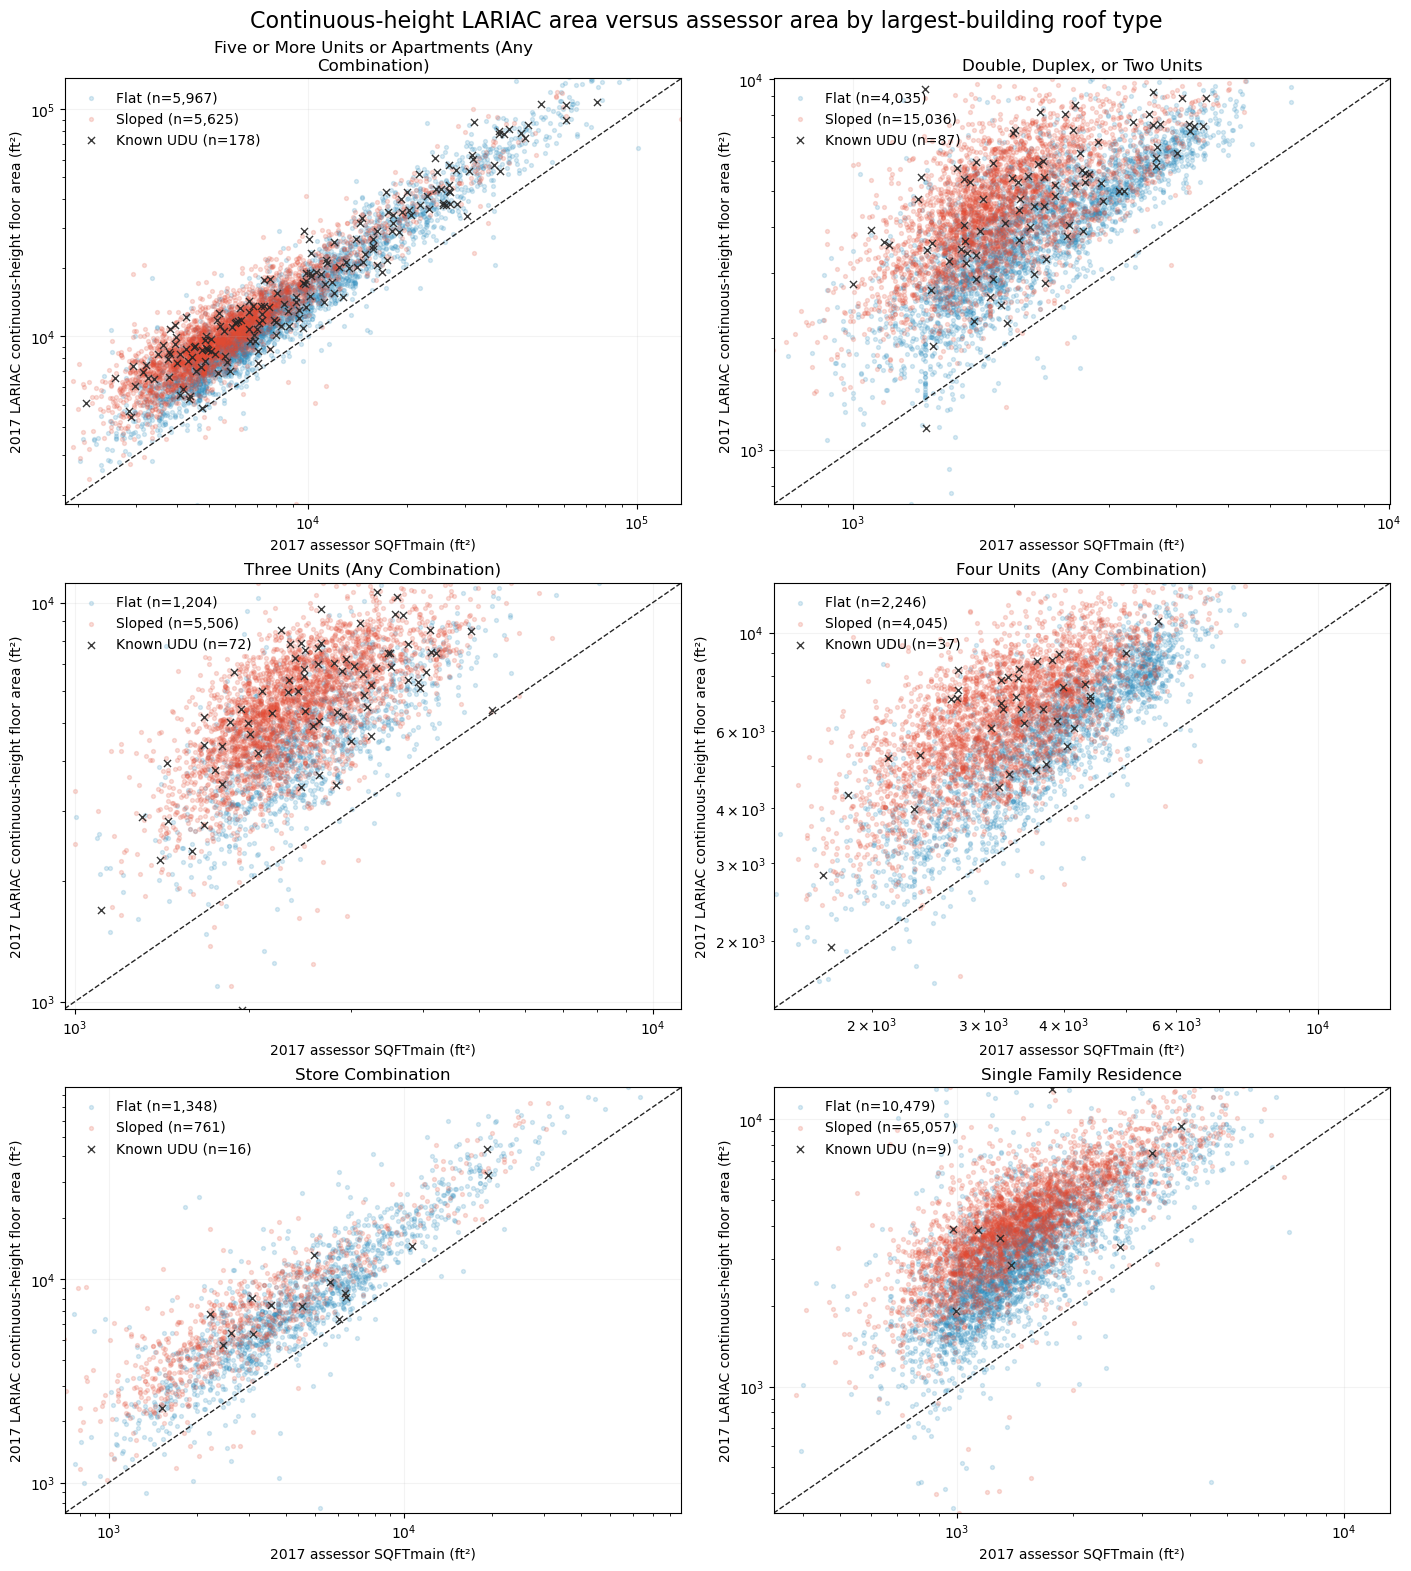

In [6]:
roof_analysis = method1_input.loc[
    method1_input['largest_building_roof_type'].isin(['flat', 'sloped'])
].copy()
roof_analysis['floor_area_to_sqft_ratio'] = (
    roof_analysis['building.floor_area_continuous']
    / roof_analysis['assessor.sqft']
)
roof_analysis['log_floor_area_to_sqft_ratio'] = np.log(
    roof_analysis['floor_area_to_sqft_ratio']
)

roof_colors = {'flat': '#2b8cbe', 'sloped': '#e34a33'}
ncols = 2
nrows = int(np.ceil(len(modeled_use_types) / ncols))
fig, axes = plt.subplots(
    nrows, ncols, figsize=(14, 5.2 * nrows), constrained_layout=True
)
axes = np.atleast_1d(axes).ravel()
for ax, use_type in zip(axes, modeled_use_types):
    group = roof_analysis.loc[
        roof_analysis['SpecificUseType'].eq(use_type)
    ]
    for sample_seed, roof_type in enumerate(['flat', 'sloped'], start=41):
        roof_group = group.loc[
            group['largest_building_roof_type'].eq(roof_type)
        ]
        non_udu = roof_group.loc[~roof_group['is_known_udu']]
        if len(non_udu) > 3000:
            non_udu = non_udu.sample(3000, random_state=sample_seed)
        ax.scatter(
            non_udu['assessor.sqft'],
            non_udu['building.floor_area_continuous'],
            s=8, alpha=0.18, color=roof_colors[roof_type], rasterized=True,
            label=f'{roof_type.title()} (n={len(roof_group):,})',
        )
    known = group.loc[group['is_known_udu']]
    ax.scatter(
        known['assessor.sqft'], known['building.floor_area_continuous'],
        s=26, alpha=0.9, color='#252525', marker='x', linewidth=1.0,
        label=f'Known UDU (n={len(known):,})',
    )
    values = pd.concat([
        group['assessor.sqft'], group['building.floor_area_continuous']
    ]).dropna()
    lower = max(10, float(values.quantile(0.001)))
    upper = float(values.quantile(0.995))
    ax.plot([lower, upper], [lower, upper], '--', color='#252525', linewidth=1)
    ax.set(xscale='log', yscale='log', xlim=(lower, upper), ylim=(lower, upper))
    ax.set_title('\n'.join(textwrap.wrap(use_type, 42)))
    ax.set_xlabel('2017 assessor SQFTmain (ft²)')
    ax.set_ylabel('2017 LARIAC continuous-height floor area (ft²)')
    ax.grid(alpha=0.15)
    ax.legend(frameon=False, loc='upper left')
for ax in axes[len(modeled_use_types):]:
    ax.remove()
fig.suptitle(
    'Continuous-height LARIAC area versus assessor area by largest-building roof type',
    fontsize=16,
)
plt.show()

In [7]:
roof_summary = (
    roof_analysis.assign(
        lariac_below_assessor=lambda frame: (
            frame['floor_area_to_sqft_ratio'].lt(1)
        )
    )
    .groupby(['SpecificUseType', 'largest_building_roof_type'])
    .agg(
        parcels=('AIN', 'size'),
        known_udu=('is_known_udu', 'sum'),
        median_lariac_to_assessor_ratio=('floor_area_to_sqft_ratio', 'median'),
        lariac_below_assessor_share=('lariac_below_assessor', 'mean'),
    )
    .reset_index()
)

roof_test_rows = []
for use_type, group in roof_analysis.groupby('SpecificUseType'):
    flat = group.loc[
        group['largest_building_roof_type'].eq('flat'),
        'log_floor_area_to_sqft_ratio',
    ].dropna()
    sloped = group.loc[
        group['largest_building_roof_type'].eq('sloped'),
        'log_floor_area_to_sqft_ratio',
    ].dropna()
    if min(len(flat), len(sloped)) < 2:
        continue
    mann_whitney_u, p_value = mannwhitneyu(
        flat, sloped, alternative='two-sided'
    )
    roof_test_rows.append({
        'SpecificUseType': use_type,
        'flat_n': len(flat),
        'sloped_n': len(sloped),
        'flat_median_ratio': np.exp(flat.median()),
        'sloped_median_ratio': np.exp(sloped.median()),
        'flat_to_sloped_median_ratio': np.exp(flat.median() - sloped.median()),
        'rank_biserial_flat_vs_sloped': (
            2 * mann_whitney_u / (len(flat) * len(sloped)) - 1
        ),
        'mann_whitney_p_value': p_value,
    })
roof_tests = pd.DataFrame(roof_test_rows)
if not roof_tests.empty:
    p_values = roof_tests['mann_whitney_p_value'].to_numpy()
    order = np.argsort(p_values)
    adjusted_sorted = np.minimum.accumulate(
        (p_values[order] * len(p_values) / np.arange(1, len(p_values) + 1))[::-1]
    )[::-1]
    adjusted = np.empty_like(adjusted_sorted)
    adjusted[order] = np.minimum(adjusted_sorted, 1.0)
    roof_tests['p_value_fdr_bh'] = adjusted

display(roof_summary.round(3))
display(roof_tests.sort_values('SpecificUseType').round(4))

,SpecificUseType,largest_building_roof_type,parcels,known_udu,median_lariac_to_assessor_ratio,lariac_below_assessor_share
0,"Double, Duplex, or Two Units",flat,4035,27,1.739,0.013
1,"Double, Duplex, or Two Units",sloped,15036,60,2.423,0.005
2,Five or More Units or Apartments (Any Combinat...,flat,5967,114,1.550,0.016
3,Five or More Units or Apartments (Any Combinat...,sloped,5625,64,1.826,0.008
4,Four Units (Any Combination),flat,2246,9,1.546,0.016
5,Four Units (Any Combination),sloped,4045,28,1.978,0.006
6,Single Family Residence,flat,10479,3,2.070,0.017
7,Single Family Residence,sloped,65057,6,2.738,0.006
8,Store Combination,flat,1348,7,1.701,0.028
9,Store Combination,sloped,761,9,2.127,0.012


,SpecificUseType,flat_n,sloped_n,flat_median_ratio,sloped_median_ratio,flat_to_sloped_median_ratio,rank_biserial_flat_vs_sloped,mann_whitney_p_value,p_value_fdr_bh
0,"Double, Duplex, or Two Units",4035,15036,1.7392,2.4232,0.7177,-0.5934,0.0,0.0
1,Five or More Units or Apartments (Any Combinat...,5967,5625,1.5498,1.8259,0.8488,-0.4660,0.0,0.0
2,Four Units (Any Combination),2246,4045,1.5458,1.9778,0.7816,-0.5975,0.0,0.0
3,Single Family Residence,10479,65057,2.0697,2.7384,0.7558,-0.4883,0.0,0.0
4,Store Combination,1348,761,1.7014,2.1272,0.7998,-0.3829,0.0,0.0
5,Three Units (Any Combination),1204,5506,1.7301,2.2677,0.7629,-0.5565,0.0,0.0


In [8]:
roof_summary

,SpecificUseType,largest_building_roof_type,parcels,known_udu,median_lariac_to_assessor_ratio,lariac_below_assessor_share
0,"Double, Duplex, or Two Units",flat,4035,27,1.739246,0.013135
1,"Double, Duplex, or Two Units",sloped,15036,60,2.423242,0.004722
2,Five or More Units or Apartments (Any Combinat...,flat,5967,114,1.549803,0.016256
3,Five or More Units or Apartments (Any Combinat...,sloped,5625,64,1.825854,0.007644
4,Four Units (Any Combination),flat,2246,9,1.545832,0.016474
5,Four Units (Any Combination),sloped,4045,28,1.977820,0.005933
6,Single Family Residence,flat,10479,3,2.069683,0.016891
7,Single Family Residence,sloped,65057,6,2.738417,0.005979
8,Store Combination,flat,1348,7,1.701379,0.028190
9,Store Combination,sloped,761,9,2.127213,0.011827


### Flat- and sloped-roof parcels to inspect

For every modeled use type and roof class, the table selects the parcels nearest the 10th, 30th, 50th, 70th, and 90th percentiles of the LARIAC-to-assessor ratio. These deterministic examples span each group's distribution and are more informative than arbitrary rows.

In [9]:
roof_examples_source = roof_analysis.copy()
roof_examples_source['ratio_percentile_within_group'] = (
    roof_examples_source.groupby([
        'SpecificUseType', 'largest_building_roof_type'
    ])['floor_area_to_sqft_ratio'].rank(pct=True)
)
roof_examples_source['lariac_minus_assessor_sqft'] = (
    roof_examples_source['building.floor_area_continuous']
    - roof_examples_source['assessor.sqft']
)
target_percentiles = [0.10, 0.30, 0.50, 0.70, 0.90]
example_groups = []
for (use_type, roof_type), group in roof_examples_source.groupby(
    ['SpecificUseType', 'largest_building_roof_type'], sort=False
):
    example_indices = [
        (group['ratio_percentile_within_group'] - target).abs().idxmin()
        for target in target_percentiles
    ]
    examples = group.loc[example_indices].copy()
    examples['target_ratio_percentile'] = target_percentiles
    example_groups.append(examples)

roof_examples = pd.concat(example_groups, ignore_index=True)
roof_examples['SpecificUseType'] = pd.Categorical(
    roof_examples['SpecificUseType'], categories=modeled_use_types, ordered=True
)
roof_examples['largest_building_roof_type'] = pd.Categorical(
    roof_examples['largest_building_roof_type'],
    categories=['flat', 'sloped'], ordered=True,
)
roof_examples = (
    roof_examples[[
        'SpecificUseType', 'largest_building_roof_type',
        'target_ratio_percentile', 'AIN', 'largest_building_id',
        'largest_building_footprint_sqft',
        'largest_building_median_slope_deg', 'assessor.sqft',
        'building.floor_area_continuous', 'floor_area_to_sqft_ratio',
        'lariac_minus_assessor_sqft', 'is_known_udu',
    ]]
    .sort_values([
        'SpecificUseType', 'largest_building_roof_type',
        'target_ratio_percentile',
    ])
    .reset_index(drop=True)
)
display(roof_summary.round(3))
with pd.option_context('display.max_rows', None):
    display(roof_examples.round(3))

,SpecificUseType,largest_building_roof_type,parcels,known_udu,median_lariac_to_assessor_ratio,lariac_below_assessor_share
0,"Double, Duplex, or Two Units",flat,4035,27,1.739,0.013
1,"Double, Duplex, or Two Units",sloped,15036,60,2.423,0.005
2,Five or More Units or Apartments (Any Combinat...,flat,5967,114,1.550,0.016
3,Five or More Units or Apartments (Any Combinat...,sloped,5625,64,1.826,0.008
4,Four Units (Any Combination),flat,2246,9,1.546,0.016
5,Four Units (Any Combination),sloped,4045,28,1.978,0.006
6,Single Family Residence,flat,10479,3,2.070,0.017
7,Single Family Residence,sloped,65057,6,2.738,0.006
8,Store Combination,flat,1348,7,1.701,0.028
9,Store Combination,sloped,761,9,2.127,0.012


,SpecificUseType,largest_building_roof_type,target_ratio_percentile,AIN,largest_building_id,largest_building_footprint_sqft,largest_building_median_slope_deg,assessor.sqft,building.floor_area_continuous,floor_area_to_sqft_ratio,lariac_minus_assessor_sqft,is_known_udu
0,Five or More Units or Apartments (Any Combinat...,flat,0.1,2653016060,424454904701,4160.379,1.203,7168,8815.40,1.230,1647.40,False
1,Five or More Units or Apartments (Any Combinat...,flat,0.3,5402021014,479811850377,5343.974,0.971,8478,11933.09,1.408,3455.09,False
2,Five or More Units or Apartments (Any Combinat...,flat,0.5,2219009006,425662895152,6366.874,2.138,9038,14007.12,1.550,4969.12,False
3,Five or More Units or Apartments (Any Combinat...,flat,0.7,5540017002,473240857124,7047.746,2.617,25006,42652.96,1.706,17646.96,False
4,Five or More Units or Apartments (Any Combinat...,flat,0.9,2162013008,404694882609,53267.886,1.189,107886,216747.03,2.009,108861.03,False
5,Five or More Units or Apartments (Any Combinat...,sloped,0.1,5054015015,471966833465,5241.413,5.950,15252,22265.52,1.460,7013.52,False
6,Five or More Units or Apartments (Any Combinat...,sloped,0.3,2506035041,424116931456,2442.462,18.122,4810,8026.24,1.669,3216.24,False
7,Five or More Units or Apartments (Any Combinat...,sloped,0.5,7410018037,468656748821,3732.828,13.354,4731,8637.76,1.826,3906.76,False
8,Five or More Units or Apartments (Any Combinat...,sloped,0.7,5060024023,463699836256,2064.988,29.129,4428,8909.95,2.012,4481.95,False
9,Five or More Units or Apartments (Any Combinat...,sloped,0.9,5109013004,480429823832,2606.029,20.779,4622,10931.02,2.365,6309.02,False


### Interpreting the roof comparison

The Mann–Whitney tests compare the log LARIAC-to-assessor ratio for flat versus sloped largest buildings within each use type. `rank_biserial_flat_vs_sloped` supplies the effect direction and magnitude: a negative value means flat-roof parcels tend to have lower ratios. Because the samples are large, practical interpretation should emphasize the two medians, their ratio, and rank-biserial effect—not statistical significance alone. These are descriptive associations within the transferred 300-tract roof coverage; they do not establish that roof form causes an area discrepancy.

In [10]:
# AIN-level scores for the cross-method comparison in notebook 04. This is an
# intermediate file, separate from the final output above.
METHOD_SCORES_DIR = PROJECT_ROOT / 'data/02_intermediate/method_scores'
METHOD_SCORES_DIR.mkdir(parents=True, exist_ok=True)
method1_features.to_parquet(METHOD_SCORES_DIR / 'method1_scores_2017.parquet', index=False)
print(f'Saved {len(method1_features):,} AIN rows to {METHOD_SCORES_DIR / "method1_scores_2017.parquet"}')

Saved 535,193 AIN rows to /Users/adamswietek/Documents/NDSC_HiddenHousing/data/02_intermediate/method_scores/method1_scores_2017.parquet


## Spatial pattern of agreement

AIN center points come from `all_parcel_data` (2016 roll centers, the closest available to 2017, falling back to 2024) and are aggregated into hexagons, so that hundreds of thousands of AINs render quickly. `plot_ain_hexbin` accepts any DataFrame with an AIN column and a numeric or boolean metric column. Each hexagon shows the metric reduced over its AINs (the median by default). Hexagons with fewer than `min_count` AINs are left blank.

In [11]:
import sys

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from src.viz import AIN_POINT_CRS, plot_ain_hexbin


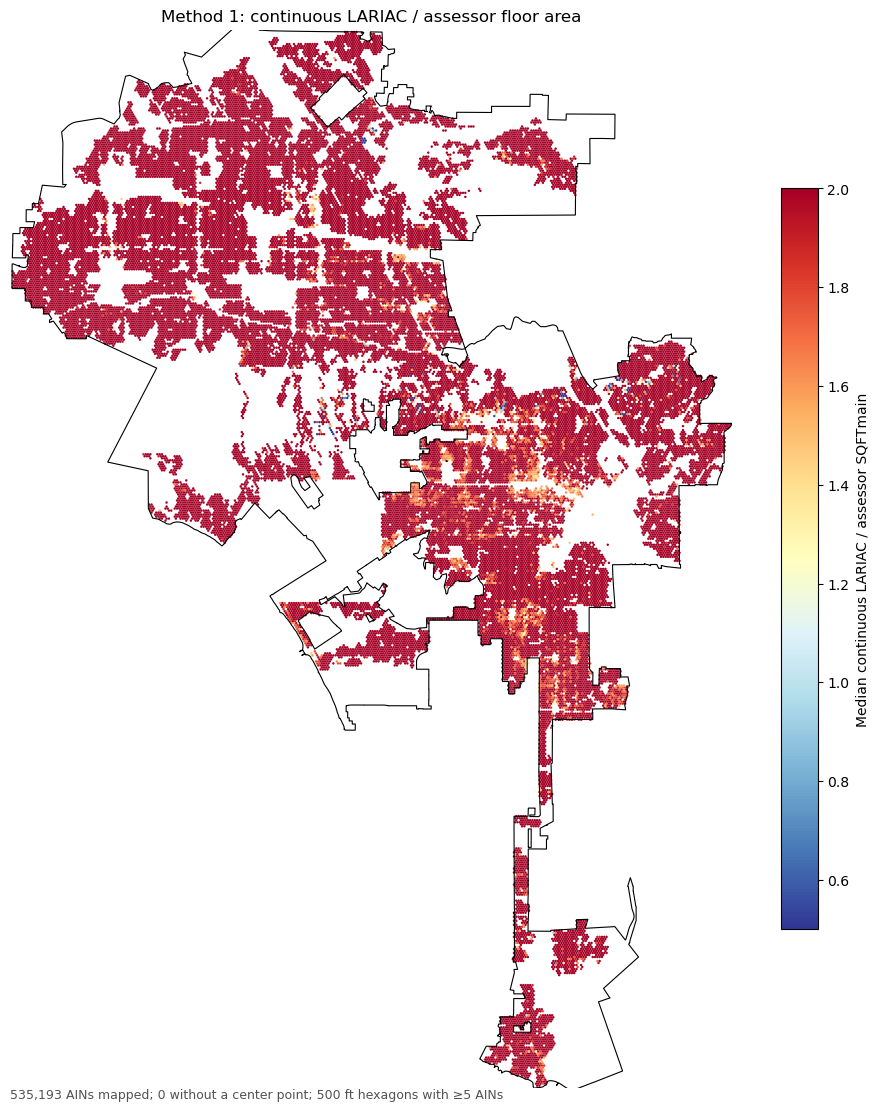

In [12]:
# The ratio is centered conceptually on 1 (exact agreement).
fig, ax = plt.subplots(figsize=(11, 11), constrained_layout=True)

plot_ain_hexbin(
    method1_features, 'floor_area_to_sqft_ratio', ax=ax,
    cmap='RdYlBu_r', vmin=0.5, vmax=2, hex_width_ft=500,
    title='Method 1: continuous LARIAC / assessor floor area',
    colorbar_label='Median continuous LARIAC / assessor SQFTmain',
)

import geopandas as gpd
# GeoJSON is WGS84; the hexbins are in EPSG:2229 feet.
lac = gpd.read_file(PROJECT_ROOT / 'data/01_source/lacity_boundary.geojson')
xlim, ylim = ax.get_xlim(), ax.get_ylim()
lac.to_crs(AIN_POINT_CRS).boundary.plot(ax=ax, color='k', linewidth=0.8)
ax.set_xlim(xlim)
ax.set_ylim(ylim)
plt.show()


## Sensitivity appendix: former integer-floor estimate

This section preserves the former `footprint × ⌊height / 10 ft⌋` estimate as a sensitivity analysis. It explains why that discrete version often fell below assessor `SQFTmain`, and why Method 1 now uses the continuous field. Each discrete undershoot is assigned the first diagnostic scenario that lifts its ratio to 1; these are sensitivity tests, not verified causes:

1. **Zero-floor structures.** Buildings under 10 ft get zero floors and add no floor area. Test: counting every structure as at least one floor lifts the ratio to 1 or more.
2. **Floor truncation.** ⌊height / 10⌋ discards fractional floors, so a 19 ft house counts as one floor. Test: continuous height (footprint × height / 10 ft) lifts the ratio to 1 or more.
3. **Partial-story rounding.** Rounding every positive height interval up to a whole floor lifts the ratio to 1, even though continuous height does not. This is an intentionally generous upper-bound test.
4. **Recent construction.** Assessor year built is 2016 or later, so the structure may be incomplete or absent in the 2017 imagery.
5. **Parcel matching.** At least one building was assigned by maximum overlap, or a matched building has less than 90% of its footprint on the parcel.
6. **Unexplained after rounding up.** None of the above: the detected footprint remains too small for the recorded area even when every partial story is counted as a full story. Candidates include missing structures, basements, unusual roof geometry, and roll errors.

In [13]:
from src.metrics import FLOOR_HEIGHT_FT

undershoot_site_columns = [
    'site_id', 'building.count', 'building.footprint_area', 'building.volume',
    'snapshot.coverage', 'match.overlap_ratio.min', 'match.n_overlap_resolved',
    'assessor.units', 'assessor.year_built',
]
undershoot_sites, _ = load_city_table('parcel_metrics_2017.parquet', undershoot_site_columns)
undershoot_sites = undershoot_sites.drop_duplicates('site_id')

site_buildings, _ = load_city_table(
    'building_metrics_2017.parquet', ['structure_id', 'site_id', 'shape.area', 'height']
)
site_buildings = site_buildings.dropna(subset=['site_id']).drop_duplicates('structure_id')
site_buildings['height'] = pd.to_numeric(site_buildings['height'], errors='coerce')
building_area = pd.to_numeric(site_buildings['shape.area'], errors='coerce')
building_floors = np.floor(site_buildings['height'] / FLOOR_HEIGHT_FT)
site_buildings = site_buildings.assign(
    min_one_floor_area=building_area * np.maximum(building_floors, 1),
    rounded_up_floor_area=(
        building_area
        * np.maximum(np.ceil(site_buildings['height'] / FLOOR_HEIGHT_FT), 1)
    ),
    zero_floor_area=building_area.where(building_floors.lt(1), 0.0),
).groupby('site_id').agg(
    min_one_floor_area=('min_one_floor_area', 'sum'),
    rounded_up_floor_area=('rounded_up_floor_area', 'sum'),
    zero_floor_area=('zero_floor_area', 'sum'),
    max_height_ft=('height', 'max'),
)

undershoot = (
    method1_input[[
        'AIN', 'site_id', 'SpecificUseType', 'is_known_udu',
        'largest_building_id', 'largest_building_footprint_sqft',
        'largest_building_median_slope_deg', 'largest_building_roof_type',
        'assessor.sqft', 'building.floor_area',
        'building.floor_area_continuous',
    ]]
    .merge(undershoot_sites, on='site_id', how='left', validate='many_to_one')
    .merge(site_buildings, on='site_id', how='left', validate='many_to_one')
)
assessor_sqft = undershoot['assessor.sqft']
undershoot['ratio'] = undershoot['building.floor_area'] / assessor_sqft
undershoot['ratio_min_one_floor'] = undershoot['min_one_floor_area'] / assessor_sqft
undershoot['ratio_continuous_height'] = (
    undershoot['building.volume'] / FLOOR_HEIGHT_FT / assessor_sqft
)
undershoot['ratio_rounded_up_height'] = (
    undershoot['rounded_up_floor_area'] / assessor_sqft
)
undershoot['ratio_footprint'] = undershoot['building.footprint_area'] / assessor_sqft
undershoot['mean_height_ft'] = (
    undershoot['building.volume'] / undershoot['building.footprint_area']
)
undershoot['zero_floor_share'] = (
    undershoot['zero_floor_area'] / undershoot['building.footprint_area']
)
undershoot['is_undershoot'] = undershoot['ratio'].lt(1)
undershoot['is_severe_undershoot'] = undershoot['ratio'].lt(0.75)
undershoot['is_continuous_shortfall'] = (
    undershoot['ratio_continuous_height'].lt(1)
)
matching_issue = (
    undershoot['match.n_overlap_resolved'].fillna(0).gt(0)
    | undershoot['match.overlap_ratio.min'].lt(0.9)
)
undershoot['undershoot_driver'] = np.select(
    [
        ~undershoot['is_undershoot'],
        undershoot['ratio_min_one_floor'].ge(1),
        undershoot['ratio_continuous_height'].ge(1),
        undershoot['ratio_rounded_up_height'].ge(1),
        undershoot['assessor.year_built'].ge(2016),
        matching_issue,
    ],
    [
        'not undershooting', 'zero-floor structures', 'floor truncation',
        'partial-story rounding', 'recent construction', 'parcel matching',
    ],
    default='unexplained',
)
DRIVER_ORDER = [
    'zero-floor structures', 'floor truncation', 'partial-story rounding',
    'recent construction', 'parcel matching', 'unexplained',
]
under = undershoot.loc[undershoot['is_undershoot']]

display(
    undershoot.groupby('SpecificUseType').agg(
        parcels=('AIN', 'size'),
        undershoot_share=('is_undershoot', 'mean'),
        severe_share=('is_severe_undershoot', 'mean'),
    )
    .join(under.groupby('SpecificUseType').agg(
        median_ratio_when_under=('ratio', 'median'),
        median_footprint_ratio_when_under=('ratio_footprint', 'median'),
        median_height_ft_when_under=('mean_height_ft', 'median'),
        known_udu_under=('is_known_udu', 'sum'),
    ))
    .sort_values('parcels', ascending=False)
    .round(3)
)
display(
    pd.crosstab(under['SpecificUseType'], under['undershoot_driver'], normalize='index')
    .reindex(columns=DRIVER_ORDER, fill_value=0)
    .assign(undershooting_parcels=under['SpecificUseType'].value_counts())
    .sort_values('undershooting_parcels', ascending=False)
    .round(3)
)
display(pd.Series({
    'undershooting parcels': len(under),
    'recovered by counting every structure as one floor or more': under['ratio_min_one_floor'].ge(1).mean(),
    'recovered by continuous height': under['ratio_continuous_height'].ge(1).mean(),
    'recovered by rounding every partial story up': under['ratio_rounded_up_height'].ge(1).mean(),
    'footprint alone at least assessor area': under['ratio_footprint'].ge(1).mean(),
    'with at least one zero-floor structure': under['zero_floor_share'].gt(0).mean(),
}, name='share of undershooting parcels').to_frame().round(3))

# How much of the ratio screen's potential non-UDU flag is estimation artifact?
ratio_flags = undershoot.merge(
    method1_features[['AIN', 'method1_ratio_potential_nonudu']],
    on='AIN', how='left', validate='one_to_one',
)
ratio_flags = ratio_flags.loc[ratio_flags['method1_ratio_potential_nonudu'].eq(True)]
display(
    ratio_flags['undershoot_driver'].value_counts(normalize=True)
    .reindex(['not undershooting', *DRIVER_ORDER], fill_value=0)
    .rename(f'share of {len(ratio_flags):,} ratio-screen flags').to_frame().round(3)
)

,parcels,undershoot_share,severe_share,median_ratio_when_under,median_footprint_ratio_when_under,median_height_ft_when_under,known_udu_under
SpecificUseType,,,,,,,
Single Family Residence,430850,0.032,0.023,0.0,1.340,9.370,0
"Double, Duplex, or Two Units",42868,0.051,0.03,0.671,1.164,11.596,8
Five or More Units or Apartments (Any Combination),29213,0.089,0.058,0.684,0.655,18.700,18
Three Units (Any Combination),13650,0.058,0.028,0.766,0.999,13.396,5
Four Units (Any Combination),13396,0.066,0.04,0.671,0.731,17.615,2
Store Combination,5216,0.129,0.053,0.845,0.779,16.620,2


undershoot_driver,zero-floor structures,floor truncation,partial-story rounding,recent construction,parcel matching,unexplained,undershooting_parcels
SpecificUseType,,,,,,,
Single Family Residence,0.636,0.266,0.035,0.0,0.012,0.052,13757
Five or More Units or Apartments (Any Combination),0.070,0.781,0.079,0.0,0.030,0.040,2599
"Double, Duplex, or Two Units",0.588,0.330,0.042,0.0,0.007,0.033,2175
Four Units (Any Combination),0.189,0.683,0.087,0.0,0.009,0.033,890
Three Units (Any Combination),0.505,0.440,0.031,0.0,0.004,0.020,794
Store Combination,0.248,0.600,0.082,0.0,0.031,0.039,673


,share of undershooting parcels
undershooting parcels,20888.000
recovered by counting every structure as one floor or more,0.524
recovered by continuous height,0.751
recovered by rounding every partial story up,0.940
footprint alone at least assessor area,0.519
with at least one zero-floor structure,0.608


,"share of 26,756 ratio-screen flags"
undershoot_driver,
not undershooting,0.466
zero-floor structures,0.287
floor truncation,0.166
partial-story rounding,0.035
recent construction,0.000
parcel matching,0.011
unexplained,0.036


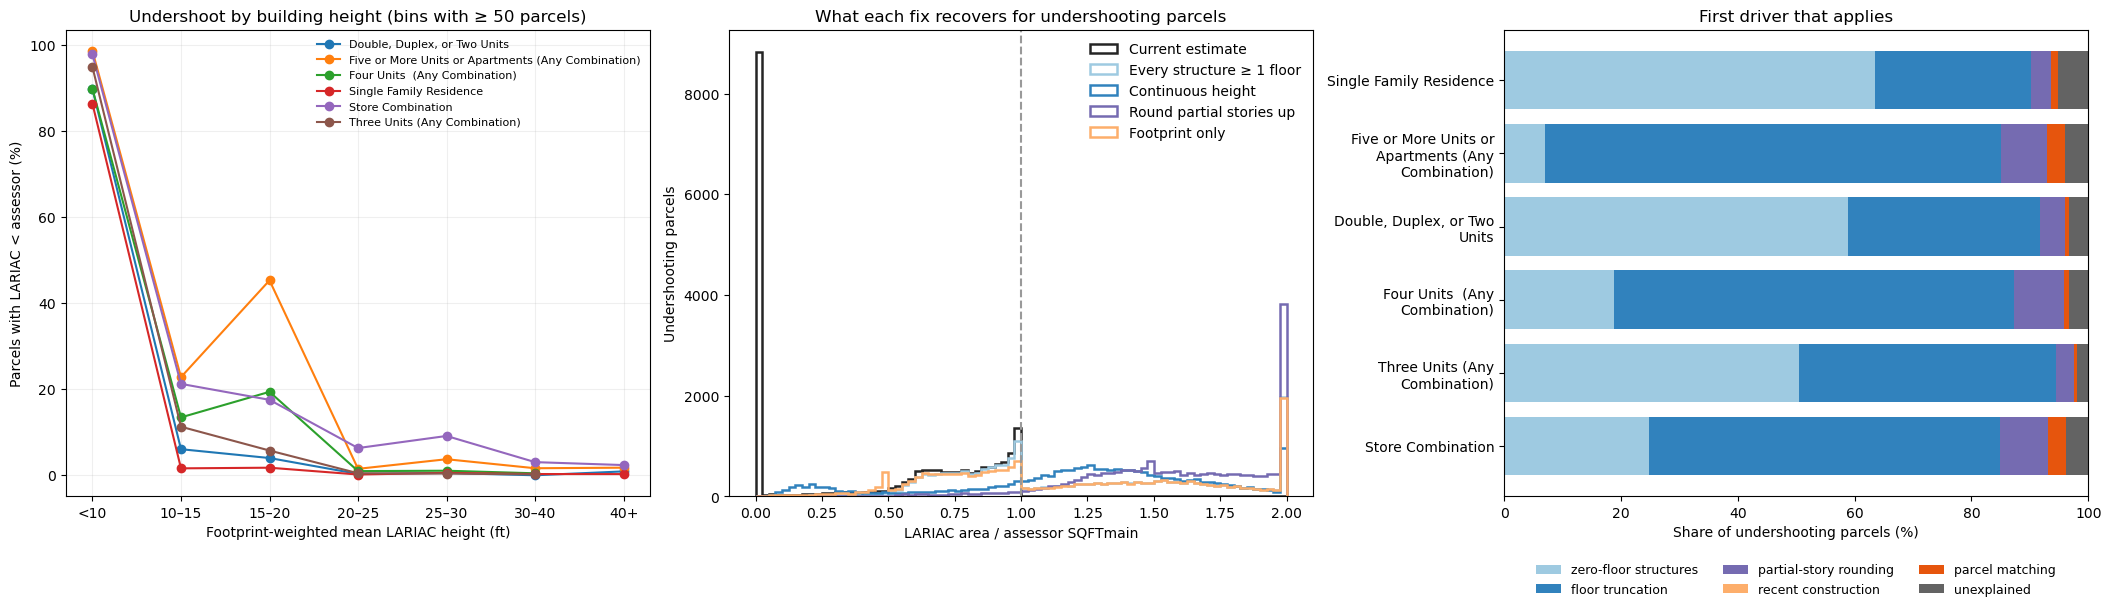

,AIN,SpecificUseType,assessor.sqft,building.floor_area,ratio,ratio_continuous_height,ratio_rounded_up_height,ratio_footprint,building.count,mean_height_ft,max_height_ft,zero_floor_share,assessor.year_built,match.overlap_ratio.min,undershoot_driver
0,7559007021,Single Family Residence,1305,0.0,0.0,1.80,1.81,1.81,1,9.91,9.91,1.0,1955.0,1.0,zero-floor structures
1,7559009032,Single Family Residence,1992,0.0,0.0,1.48,1.53,1.53,1,9.73,9.73,1.0,1955.0,1.0,zero-floor structures
2,7559011011,Single Family Residence,1305,0.0,0.0,1.79,2.09,2.09,2,8.57,9.34,1.0,1955.0,1.0,zero-floor structures
3,7559012015,Single Family Residence,1834,0.0,0.0,1.41,1.43,1.43,1,9.82,9.82,1.0,1955.0,1.0,zero-floor structures
4,7559014010,Single Family Residence,1860,0.0,0.0,1.48,1.59,1.59,1,9.32,9.32,1.0,1954.0,1.0,zero-floor structures
5,7559014027,Single Family Residence,1567,0.0,0.0,1.52,1.85,1.85,1,8.19,8.19,1.0,1955.0,1.0,zero-floor structures
6,7559014028,Single Family Residence,1460,0.0,0.0,1.95,2.15,2.15,1,9.07,9.07,1.0,1955.0,1.0,zero-floor structures
7,7559017007,Single Family Residence,1972,0.0,0.0,1.64,1.69,1.69,1,9.75,9.75,1.0,1955.0,1.0,zero-floor structures
8,7559017009,Single Family Residence,1540,0.0,0.0,1.42,1.49,1.49,1,9.55,9.55,1.0,1955.0,1.0,zero-floor structures
9,7559017011,Single Family Residence,2006,0.0,0.0,1.53,1.62,1.62,1,9.42,9.42,1.0,1955.0,1.0,zero-floor structures


In [14]:
height_bins = [0, 10, 15, 20, 25, 30, 40, np.inf]
height_labels = ['<10', '10–15', '15–20', '20–25', '25–30', '30–40', '40+']
undershoot['height_bin'] = pd.cut(
    undershoot['mean_height_ft'], height_bins, right=False, labels=height_labels
)
driver_colors = {
    'zero-floor structures': '#9ecae1', 'floor truncation': '#3182bd',
    'partial-story rounding': '#756bb1',
    'recent construction': '#fdae6b', 'parcel matching': '#e6550d',
    'unexplained': '#636363',
}

fig, axes = plt.subplots(1, 3, figsize=(21, 6), constrained_layout=True)
ax = axes[0]
by_height = undershoot.groupby(['SpecificUseType', 'height_bin'], observed=True).agg(
    parcels=('AIN', 'size'), share=('is_undershoot', 'mean'),
).reset_index()
for use_type, group in by_height.loc[by_height['parcels'].ge(50)].groupby('SpecificUseType'):
    ax.plot(group['height_bin'].astype(str), 100 * group['share'], marker='o', label=use_type)
ax.set(
    xlabel='Footprint-weighted mean LARIAC height (ft)',
    ylabel='Parcels with LARIAC < assessor (%)',
    title='Undershoot by building height (bins with ≥ 50 parcels)',
)
ax.grid(alpha=0.2)
ax.legend(frameon=False, fontsize=8)

ax = axes[1]
bins = np.linspace(0, 2, 81)
for column, color, label in [
    ('ratio', '#252525', 'Current estimate'),
    ('ratio_min_one_floor', '#9ecae1', 'Every structure ≥ 1 floor'),
    ('ratio_continuous_height', '#3182bd', 'Continuous height'),
    ('ratio_rounded_up_height', '#756bb1', 'Round partial stories up'),
    ('ratio_footprint', '#fdae6b', 'Footprint only'),
]:
    ax.hist(
        under[column].clip(0, 2), bins=bins, histtype='step', linewidth=1.8,
        color=color, label=label,
    )
ax.axvline(1, color='#999999', linestyle='--')
ax.set(
    xlabel='LARIAC area / assessor SQFTmain',
    ylabel='Undershooting parcels',
    title='What each fix recovers for undershooting parcels',
)
ax.legend(frameon=False)

ax = axes[2]
shares = (
    pd.crosstab(under['SpecificUseType'], under['undershoot_driver'], normalize='index')
    .reindex(columns=DRIVER_ORDER, fill_value=0)
)
shares = shares.loc[under['SpecificUseType'].value_counts().index[::-1]]
left = np.zeros(len(shares))
for driver in DRIVER_ORDER:
    ax.barh(
        ['\n'.join(textwrap.wrap(name, 26)) for name in shares.index],
        100 * shares[driver], left=left, color=driver_colors[driver], label=driver,
    )
    left += 100 * shares[driver]
ax.set(xlim=(0, 100), xlabel='Share of undershooting parcels (%)', title='First driver that applies')
ax.legend(frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=3, fontsize=9)
plt.show()

display(
    under.nsmallest(15, 'ratio')[[
        'AIN', 'SpecificUseType', 'assessor.sqft', 'building.floor_area', 'ratio',
        'ratio_continuous_height', 'ratio_rounded_up_height',
        'ratio_footprint', 'building.count',
        'mean_height_ft', 'max_height_ft', 'zero_floor_share',
        'assessor.year_built', 'match.overlap_ratio.min', 'undershoot_driver',
    ]].round(2).reset_index(drop=True)
)

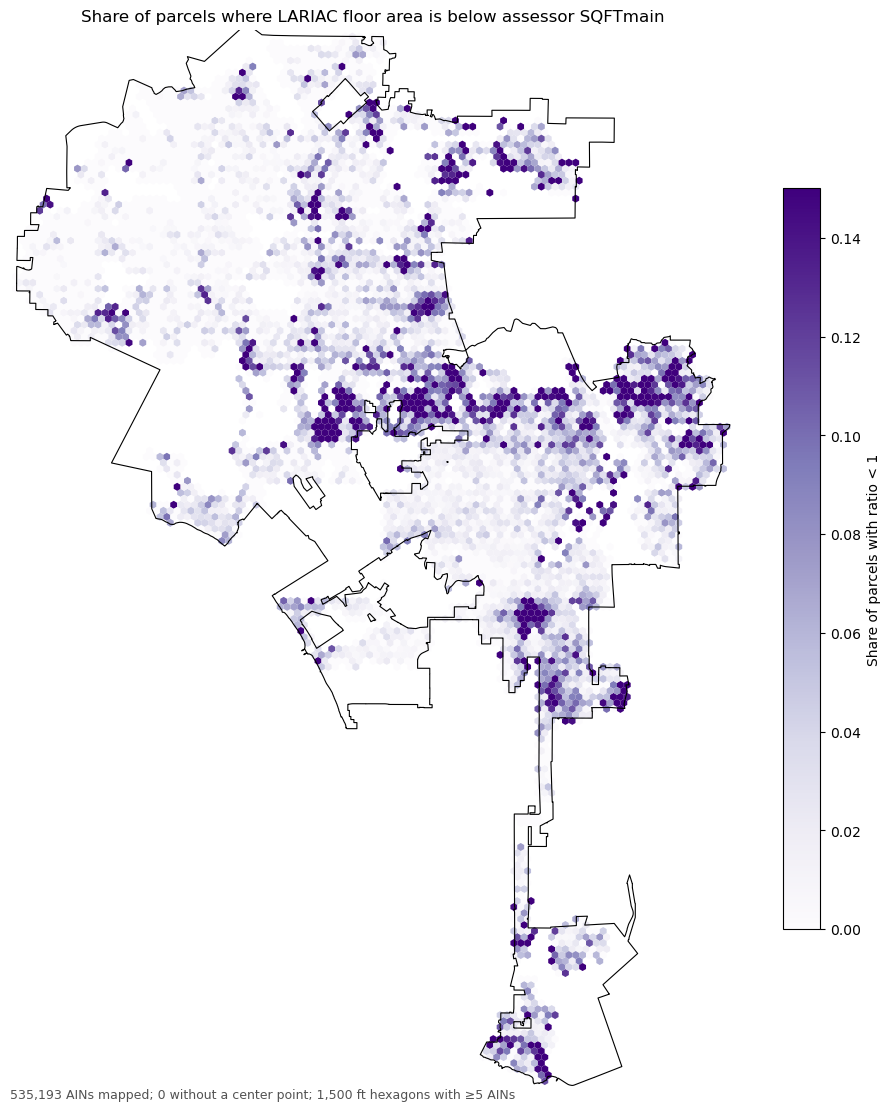

In [15]:
fig, ax = plt.subplots(figsize=(11, 11), constrained_layout=True)
plot_ain_hexbin(
    undershoot, 'is_undershoot', ax=ax, reduce_function=np.mean,
    cmap='Purples', vmin=0, vmax=0.15, hex_width_ft=1500,
    title='Share of parcels where LARIAC floor area is below assessor SQFTmain',
    colorbar_label='Share of parcels with ratio < 1',
)
city_boundary = gpd.read_file(PROJECT_ROOT / 'data/01_source/lacity_boundary.geojson')
xlim, ylim = ax.get_xlim(), ax.get_ylim()
city_boundary.to_crs(AIN_POINT_CRS).boundary.plot(ax=ax, color='k', linewidth=0.8)
ax.set_xlim(xlim)
ax.set_ylim(ylim)
plt.show()

## Why continuous LARIAC area can remain below assessor area

Here a “negative” case means a negative residual: continuous-height LARIAC floor area is below assessor `SQFTmain` (`ratio < 1`). Since assessor area is reported by AIN, these are parcel-level diagnostics, even when an AIN contains several structures. The mutually exclusive labels below are screening explanations, applied in order: parcel-matching warning, possible 2017 timing mismatch, recovery by treating every detected structure as at least one story, recovery only by rounding partial stories upward, and a gap that persists after generous rounding. They are not verified causes.

,value
continuous-height shortfall parcels,5210.000
share of all modeled parcels,0.010
known UDU continuous shortfalls,4.000
median LARIAC / assessor ratio when below 1,0.566
median shortfall (ft²),690.405


,parcels,median_ratio,median_shortfall_sqft,known_udu,share_of_shortfalls
continuous_shortfall_diagnostic,,,,,
parcel matching warning,848,0.619,715.015,0,0.163
possible construction timing mismatch,12,0.877,402.275,0,0.002
recovered by minimum one story,2644,0.423,648.940,3,0.507
recovered by rounding partial stories,743,0.906,265.610,1,0.143
persistent after generous rounding,963,0.350,1463.550,0,0.185


,SpecificUseType,largest_building_roof_type,parcels,continuous_shortfalls,continuous_shortfall_share,median_continuous_ratio,median_roof_slope_deg
0,"Double, Duplex, or Two Units",flat,4035,53,0.013,1.739,2.950
1,"Double, Duplex, or Two Units",sloped,15036,71,0.005,2.423,18.403
2,Five or More Units or Apartments (Any Combinat...,flat,5967,97,0.016,1.550,1.745
3,Five or More Units or Apartments (Any Combinat...,sloped,5625,43,0.008,1.826,16.660
4,Four Units (Any Combination),flat,2246,37,0.016,1.546,2.548
5,Four Units (Any Combination),sloped,4045,24,0.006,1.978,17.730
6,Single Family Residence,flat,10479,177,0.017,2.070,3.214
7,Single Family Residence,sloped,65057,389,0.006,2.738,18.096
8,Store Combination,flat,1348,38,0.028,1.701,2.389
9,Store Combination,sloped,761,9,0.012,2.127,13.913


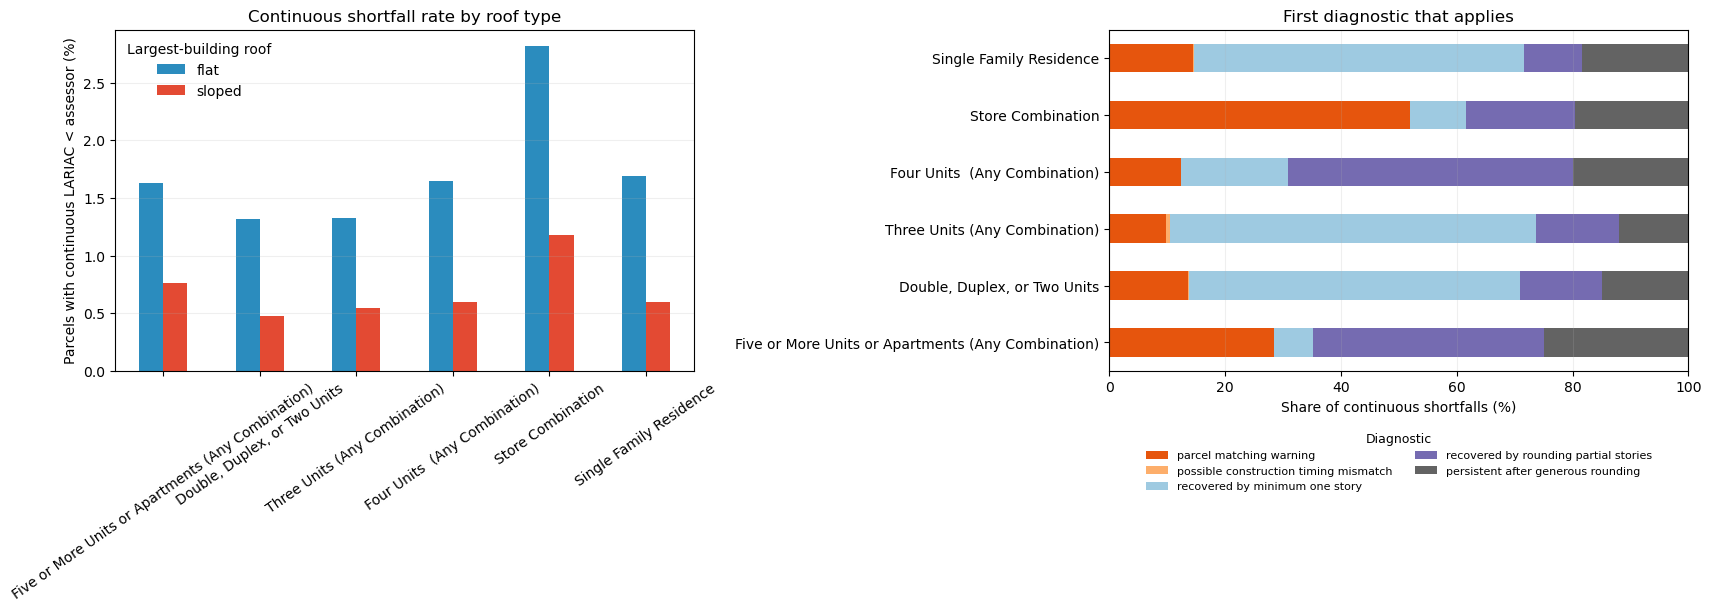

,AIN,SpecificUseType,largest_building_roof_type,largest_building_median_slope_deg,assessor.sqft,building.floor_area_continuous,ratio_continuous_height,shortfall_sqft,ratio_footprint,mean_height_ft,building.count,match.overlap_ratio.min,match.n_overlap_resolved,assessor.year_built,continuous_shortfall_diagnostic,is_known_udu
0,5401002031,Five or More Units or Apartments (Any Combinat...,NaN,NaN,85191,124.80,0.001,85066.20,0.001,11.190,1,1.00,0,1986.0,persistent after generous rounding,False
1,4492017003,Single Family Residence,NaN,NaN,2996,13.82,0.005,2982.18,0.019,2.410,1,1.00,1,1963.0,parcel matching warning,False
2,2368007004,Single Family Residence,NaN,NaN,3760,26.26,0.007,3733.74,0.048,1.460,1,1.00,0,1934.0,persistent after generous rounding,False
3,4410013016,Single Family Residence,sloped,13.231,1029,9.77,0.009,1019.23,0.053,1.790,1,1.00,1,1924.0,parcel matching warning,False
4,4356002008,Single Family Residence,NaN,NaN,5556,61.89,0.011,5494.11,0.093,1.200,1,1.00,0,1994.0,persistent after generous rounding,False
5,2385021006,Single Family Residence,NaN,NaN,1434,16.21,0.011,1417.79,0.002,53.508,1,1.00,1,1941.0,parcel matching warning,False
6,5036014017,Five or More Units or Apartments (Any Combinat...,NaN,NaN,5376,65.16,0.012,5310.84,0.014,8.419,1,1.00,0,1983.0,persistent after generous rounding,False
7,5559014009,Single Family Residence,NaN,NaN,5988,114.38,0.019,5873.62,0.022,8.820,1,1.00,0,1997.0,persistent after generous rounding,False
8,5452010006,Single Family Residence,NaN,NaN,216,4.20,0.019,211.80,0.152,1.280,1,0.29,1,1912.0,parcel matching warning,False
9,4383002009,Single Family Residence,NaN,NaN,8402,171.39,0.020,8230.61,0.021,9.570,1,1.00,0,1981.0,persistent after generous rounding,False


In [16]:
continuous_shortfall = undershoot.loc[
    undershoot['is_continuous_shortfall']
].copy()
continuous_shortfall['shortfall_sqft'] = (
    continuous_shortfall['assessor.sqft']
    - continuous_shortfall['building.floor_area_continuous']
)
continuous_shortfall['shortfall_share_of_assessor'] = (
    1 - continuous_shortfall['ratio_continuous_height']
)
continuous_shortfall['matching_warning'] = (
    continuous_shortfall['match.n_overlap_resolved'].fillna(0).gt(0)
    | continuous_shortfall['match.overlap_ratio.min'].lt(0.9)
)
continuous_shortfall['continuous_shortfall_diagnostic'] = np.select(
    [
        continuous_shortfall['matching_warning'],
        continuous_shortfall['assessor.year_built'].ge(2016),
        continuous_shortfall['ratio_min_one_floor'].ge(1),
        continuous_shortfall['ratio_rounded_up_height'].ge(1),
    ],
    [
        'parcel matching warning',
        'possible construction timing mismatch',
        'recovered by minimum one story',
        'recovered by rounding partial stories',
    ],
    default='persistent after generous rounding',
)
continuous_driver_order = [
    'parcel matching warning',
    'possible construction timing mismatch',
    'recovered by minimum one story',
    'recovered by rounding partial stories',
    'persistent after generous rounding',
]

continuous_driver_summary = (
    continuous_shortfall.groupby('continuous_shortfall_diagnostic')
    .agg(
        parcels=('AIN', 'size'),
        median_ratio=('ratio_continuous_height', 'median'),
        median_shortfall_sqft=('shortfall_sqft', 'median'),
        known_udu=('is_known_udu', 'sum'),
    )
    .reindex(continuous_driver_order, fill_value=0)
)
continuous_driver_summary['share_of_shortfalls'] = (
    continuous_driver_summary['parcels'] / len(continuous_shortfall)
)

roof_continuous_summary = (
    undershoot.dropna(subset=['largest_building_roof_type'])
    .groupby(['SpecificUseType', 'largest_building_roof_type'])
    .agg(
        parcels=('AIN', 'size'),
        continuous_shortfalls=('is_continuous_shortfall', 'sum'),
        continuous_shortfall_share=('is_continuous_shortfall', 'mean'),
        median_continuous_ratio=('ratio_continuous_height', 'median'),
        median_roof_slope_deg=('largest_building_median_slope_deg', 'median'),
    )
    .reset_index()
)

display(pd.Series({
    'continuous-height shortfall parcels': len(continuous_shortfall),
    'share of all modeled parcels': undershoot['is_continuous_shortfall'].mean(),
    'known UDU continuous shortfalls': continuous_shortfall['is_known_udu'].sum(),
    'median LARIAC / assessor ratio when below 1': (
        continuous_shortfall['ratio_continuous_height'].median()
    ),
    'median shortfall (ft²)': continuous_shortfall['shortfall_sqft'].median(),
}, name='value').to_frame().round(3))
display(continuous_driver_summary.round(3))
display(roof_continuous_summary.round(3))

fig, axes = plt.subplots(1, 2, figsize=(17, 6), constrained_layout=True)
roof_rates = (
    roof_continuous_summary.pivot(
        index='SpecificUseType', columns='largest_building_roof_type',
        values='continuous_shortfall_share',
    )
    .reindex(modeled_use_types)
    .reindex(columns=['flat', 'sloped'])
)
roof_rates.mul(100).plot.bar(
    ax=axes[0], color=[roof_colors['flat'], roof_colors['sloped']]
)
axes[0].set(
    ylabel='Parcels with continuous LARIAC < assessor (%)',
    xlabel='', title='Continuous shortfall rate by roof type',
)
axes[0].tick_params(axis='x', rotation=35)
axes[0].legend(title='Largest-building roof', frameon=False)
axes[0].grid(axis='y', alpha=0.2)

driver_shares = (
    pd.crosstab(
        continuous_shortfall['SpecificUseType'],
        continuous_shortfall['continuous_shortfall_diagnostic'],
        normalize='index',
    )
    .reindex(index=modeled_use_types, columns=continuous_driver_order, fill_value=0)
)
driver_colors = ['#e6550d', '#fdae6b', '#9ecae1', '#756bb1', '#636363']
driver_shares.mul(100).plot.barh(
    stacked=True, ax=axes[1], color=driver_colors
)
axes[1].set(
    xlim=(0, 100), xlabel='Share of continuous shortfalls (%)',
    ylabel='', title='First diagnostic that applies',
)
axes[1].legend(
    title='Diagnostic', frameon=False, fontsize=8, title_fontsize=9,
    loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=2,
)
axes[1].grid(axis='x', alpha=0.2)
plt.show()

continuous_shortfall_examples = continuous_shortfall.nsmallest(20, 'ratio_continuous_height')[[
    'AIN', 'SpecificUseType', 'largest_building_roof_type',
    'largest_building_median_slope_deg', 'assessor.sqft',
    'building.floor_area_continuous', 'ratio_continuous_height',
    'shortfall_sqft', 'ratio_footprint', 'mean_height_ft',
    'building.count', 'match.overlap_ratio.min',
    'match.n_overlap_resolved', 'assessor.year_built',
    'continuous_shortfall_diagnostic', 'is_known_udu',
]]
display(continuous_shortfall_examples.round(3).reset_index(drop=True))

### Interpretation

The tables and plots above quantify the former integer-floor field's threshold artifacts. They are counterfactual diagnostics, not parcel-level causal labels. Method 1 itself uses `building.floor_area_continuous` for its residuals, ratios, ranks, and flags.

The continuous-shortfall diagnostics distinguish likely height-conversion artifacts from matching/timing warnings and gaps that remain even under generous rounding. Recovery by a minimum one-story assumption points to implausibly low detected heights; recovery only by rounding upward points to the continuous 10-ft story conversion near a story boundary. Persistent gaps deserve footprint, basement, parcel-assignment, and assessor-scope review. Flat-roof parcels have higher shortfall rates within every displayed use type, but the roof results cover only the transferred 300-tract sample and remain associative rather than causal.

The discrepancies should not be resolved by automatically changing the conversion formula. Also, `snapshot.coverage` means building-footprint area divided by parcel area (lot coverage), not imagery coverage.

## Known UDU parcels where assessor area exceeds continuous LARIAC area

This subset uses the revised continuous-height measure and is restricted to AINs in the current UDU report and to the same single-AIN, positive-area, modeled-use-type universe used above. The list retains case timing and diagnostics. `filing_date` and `case_completion_date` describe the legalization case; they do not establish when the unpermitted unit or its enclosing structure was physically created.

In [17]:
udu_case_data = pd.read_csv(CURRENT_UDU_REPORT, encoding='utf-8-sig')
udu_case_data['AIN'] = normalize_ain(udu_case_data['assessor_parcel_number'])
udu_case_data['filing_date'] = pd.to_datetime(
    udu_case_data['filing_date'], errors='coerce'
)
udu_case_data['case_completion_date'] = pd.to_datetime(
    udu_case_data['case_completion_date'], errors='coerce'
)
# A few parcels have multiple UDU cases. Keep every case number while
# producing one diagnostic row per AIN.
udu_case_data = udu_case_data.groupby('AIN', as_index=False).agg({
    'case_number': lambda s: '; '.join(s.dropna().astype(str).unique()),
    'filing_date': 'min',
    'case_completion_date': 'max',
    'Approved Units': lambda s: s.sum(min_count=1),
    'community_plan_area': lambda s: '; '.join(s.dropna().astype(str).unique()),
})
udu_case_columns = [
    'AIN', 'case_number', 'filing_date', 'case_completion_date',
    'Approved Units', 'community_plan_area',
]

under_continuous = undershoot.loc[
    undershoot['ratio_continuous_height'].lt(1)
].copy()
udu_under = (
    under_continuous.loc[under_continuous['is_known_udu']].copy()
    .merge(udu_case_data[udu_case_columns], on='AIN', how='left', validate='one_to_one')
)
udu_under['matching_issue'] = (
    udu_under['match.n_overlap_resolved'].fillna(0).gt(0)
    | udu_under['match.overlap_ratio.min'].lt(0.9)
)
udu_under['filed_after_2017'] = (
    pd.to_datetime(udu_under['filing_date'], errors='coerce').dt.year.gt(2017)
)
udu_under['completed_after_2017'] = (
    pd.to_datetime(udu_under['case_completion_date'], errors='coerce').dt.year.gt(2017)
)
plausibility = {
    'zero-floor structures': 'high: sub-10-ft structures contributed zero area under the former integer rule',
    'floor truncation': 'high: continuous-height area reaches or exceeds assessor SQFTmain',
    'partial-story rounding': 'moderate: parity requires rounding a partial story up',
    'recent construction': 'moderate: possible 2017 timing mismatch',
    'parcel matching': 'moderate: building-to-parcel assignment needs review',
    'unexplained': 'low: not recovered by height sensitivity tests',
}
udu_under['plausibility_assessment'] = udu_under['undershoot_driver'].map(plausibility)
udu_under['secondary_matching_warning'] = np.where(
    udu_under['matching_issue'],
    'yes: inspect footprint assignment even though the height test recovers the gap',
    'no',
)

udu_under_list = (
    udu_under[[
        'AIN', 'case_number', 'SpecificUseType', 'community_plan_area',
        'filing_date', 'case_completion_date', 'Approved Units',
        'assessor.units', 'assessor.sqft', 'building.floor_area',
        'building.floor_area_continuous', 'ratio',
        'ratio_continuous_height', 'ratio_rounded_up_height',
        'building.count', 'mean_height_ft', 'zero_floor_share',
        'match.overlap_ratio.min', 'match.n_overlap_resolved',
        'matching_issue', 'assessor.year_built', 'undershoot_driver',
        'plausibility_assessment', 'secondary_matching_warning',
        'filed_after_2017', 'completed_after_2017',
    ]]
    .sort_values(['undershoot_driver', 'ratio', 'AIN'])
    .reset_index(drop=True)
)

display(pd.Series({
    'known UDU undershoots under continuous height': len(udu_under_list),
    'recovered by rounding partial stories up': udu_under['ratio_rounded_up_height'].ge(1).sum(),
    'with a secondary matching warning': udu_under['matching_issue'].sum(),
    'filed after 2017': udu_under['filed_after_2017'].sum(),
    'completed after 2017': udu_under['completed_after_2017'].sum(),
}, name='known UDU parcels').to_frame())
display(udu_under['undershoot_driver'].value_counts().rename('parcels').to_frame())
display(udu_under_list.round(3))

udu_under_path = METHOD_SCORES_DIR / 'known_udu_assessor_gt_lariac_continuous_2017.csv'
udu_under_list.to_csv(udu_under_path, index=False)
print(f'Saved {len(udu_under_list):,} known UDU rows to {udu_under_path}')


,known UDU parcels
known UDU undershoots under continuous height,4
recovered by rounding partial stories up,4
with a secondary matching warning,0
filed after 2017,3
completed after 2017,3


,parcels
undershoot_driver,
zero-floor structures,3
partial-story rounding,1


/var/folders/7b/rl6lkdns1dbfv_n3wwwmq8580000gn/T/ipykernel_20938/2936746353.py:80: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(udu_under_list.round(3))


,AIN,case_number,SpecificUseType,community_plan_area,filing_date,case_completion_date,Approved Units,assessor.units,assessor.sqft,building.floor_area,...,zero_floor_share,match.overlap_ratio.min,match.n_overlap_resolved,matching_issue,assessor.year_built,undershoot_driver,plausibility_assessment,secondary_matching_warning,filed_after_2017,completed_after_2017
0,5458016001,ADM-2018-5808-UDU,Three Units (Any Combination),Northeast Los Angeles,2017-06-22,2017-07-06,NaN,3.0,3254,1980.28,...,0.000,1.0,0,False,1916.0,partial-story rounding,moderate: parity requires rounding a partial s...,no,False,False
1,5434014003,ADM-2018-6781-UDU,"Double, Duplex, or Two Units",Hollywood,2018-02-13,2018-03-06,NaN,2.0,3288,0.0,...,1.000,1.0,0,False,1931.0,zero-floor structures,high: sub-10-ft structures contributed zero ar...,no,True,True
2,5585019026,ADM-2019-2034-UDU,Three Units (Any Combination),Hollywood,2019-03-19,2021-12-27,NaN,3.0,1947,0.0,...,1.000,1.0,0,False,1923.0,zero-floor structures,high: sub-10-ft structures contributed zero ar...,no,True,True
3,6004006002,ADM-2018-6205-UDU,"Double, Duplex, or Two Units",South Los Angeles,2018-10-08,2020-06-26,NaN,2.0,1368,60.33,...,0.965,1.0,0,False,1924.0,zero-floor structures,high: sub-10-ft structures contributed zero ar...,no,True,True


Saved 4 known UDU rows to /Users/adamswietek/Documents/NDSC_HiddenHousing/data/02_intermediate/method_scores/known_udu_assessor_gt_lariac_continuous_2017.csv


### Interpretation

The exported table is the authoritative, rerunnable list of known UDU cases where assessor area still exceeds the continuous-height LARIAC estimate. Its height, rounding, timing, and matching fields support visual review without treating any diagnostic as a verified cause.